# 14 · Use the SPT-NRTL parameter collection

This notebook loads **actual SPT-NRTL v3 predictions** for water/ethanol and
benzene/water/ethanol. It demonstrates full temperature dependence, activities,
excess properties, VLE, provenance, offline reuse and model export.

The first run needs internet access to `raw.githubusercontent.com`, unless the
needed tables are already cached or a local collection is configured. Only
needed component tables are fetched; no full-database download is required.
Install the standard Conda environment, or use
`python -m pip install -e ".[nrtl-spt,tutorials]"` from the checkout root.
Julia, model weights and COSMO input files are not needed. Run all cells in
order from `tutorials/`, beside `data/real_mixtures.json`.

The parameters are **machine-learning predictions**, not individual fits to
measured data. Cite [Winter et al. (2023)](https://doi.org/10.1016/j.fluid.2023.113731).
The [pinned v3 mirror](https://github.com/ClapeyronThermo/spt-nrtl-db/tree/f8e903ad96ac1a6d9c3dbaaa53c1752e8106286e)
contains no per-pair experimental references or validated temperature ranges.
The temperatures plotted here illustrate model evaluation, not established
validity limits or experimental agreement.

<a class="md-button" href="14_spt_nrtl_parameters.ipynb" download>Download notebook</a>


In [1]:
import json
import tempfile
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import NRTL
from thermoweave.nrtl import SPTNRTLDatabase
from thermoweave.equilibrium.vle import bubble_pressure

collection = SPTNRTLDatabase()
print("Indexed component tables:", len(collection.available_smiles))
# RDKit turns OCC into canonical CCO before lookup.
model = NRTL.from_spt({"water": "O", "ethanol": "OCC"}, database=collection)
print("Canonical SMILES:", model.metadata["component_smiles"])
print("Parameter source:", model.reference)
print("Source kind:", model.metadata["source_kind"])
print("Validated temperature range:", model.metadata["temperature_range_K"])
for pair in model.metadata["pairs"]:
    print("Source row order:", pair["source_smiles"])
    print("Source table:", pair["source_url"])
    print("Table SHA-256:", pair["table_sha256"])
    print("Pair experimental reference:", pair["experimental_reference"])

Indexed component tables: 9823
Canonical SMILES: {'water': 'O', 'ethanol': 'CCO'}
Parameter source: Winter et al. (2023), SPT-NRTL, https://doi.org/10.1016/j.fluid.2023.113731; v3, https://github.com/ClapeyronThermo/spt-nrtl-db/tree/f8e903ad96ac1a6d9c3dbaaa53c1752e8106286e
Source kind: prediction
Validated temperature range: None
Source row order: ['CCO', 'O']
Source table: https://raw.githubusercontent.com/ClapeyronThermo/spt-nrtl-db/f8e903ad96ac1a6d9c3dbaaa53c1752e8106286e/v3/C/3/CCO.csv
Table SHA-256: 903e2fcbd174ec2dac61fbf56c093beb029219b7622f2f5d446b014695723981
Pair experimental reference: None


## Full temperature dependence

SPT-NRTL uses
$\tau_{ij}=a_{ij}+b_{ij}/T+l_{ij}\ln(T/\mathrm{K})+d_{ij}T$
and $\alpha_{ij}(T)=\alpha^0_{ij}+e_{ij}T$.
In ThermoWeave l, d and e are `tau_log`, `tau_linear`, and `alpha_linear`.
a, l and alpha0 are dimensionless, b is in K, and d/e are in 1/K.

The extra terms default to zero for ordinary NRTL models, preserving a+b/T.
They remain fully active for this collection, including derivatives through
alpha(T). `interaction_parameters(T)` exposes effective tau/alpha without JAX.
Batched activities, temperature/composition derivatives and fitting use compiled
JAX kernels. Database access only occurs during model construction.

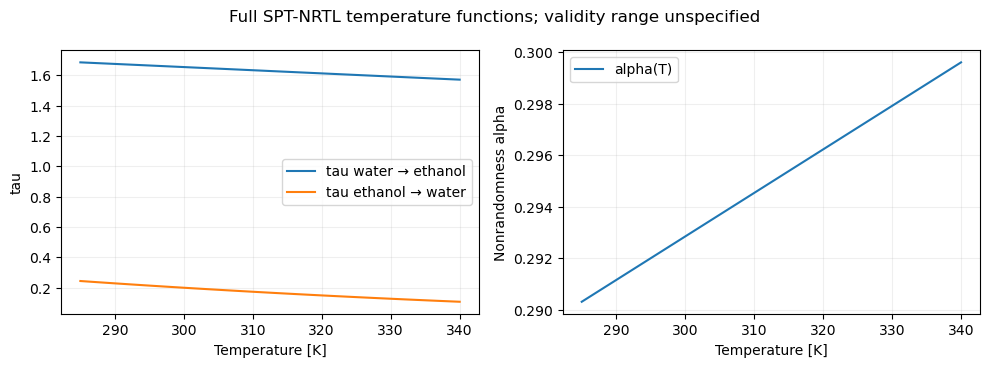

In [2]:
temperature_grid = np.linspace(285., 340., 70)
effective = [model.interaction_parameters(float(T)) for T in temperature_grid]
tau_values = np.array([item[0] for item in effective])
alpha_values = np.array([item[1] for item in effective])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
axes[0].plot(temperature_grid, tau_values[:, 0, 1], label="tau water → ethanol")
axes[0].plot(temperature_grid, tau_values[:, 1, 0], label="tau ethanol → water")
axes[0].set_ylabel("tau")
axes[1].plot(temperature_grid, alpha_values[:, 0, 1], label="alpha(T)")
axes[1].set_ylabel("Nonrandomness alpha")
for ax in axes:
    ax.set_xlabel("Temperature [K]"); ax.grid(alpha=0.2); ax.legend()
fig.suptitle("Full SPT-NRTL temperature functions; validity range unspecified")
fig.tight_layout(); plt.show()

## Activities and caloric properties

All results below are predictions of the imported model. Chemical activities
use the pure-liquid reference state. Excess enthalpy and heat capacity follow
temperature derivatives of the same Gibbs function; they are not independent
experimental validation.

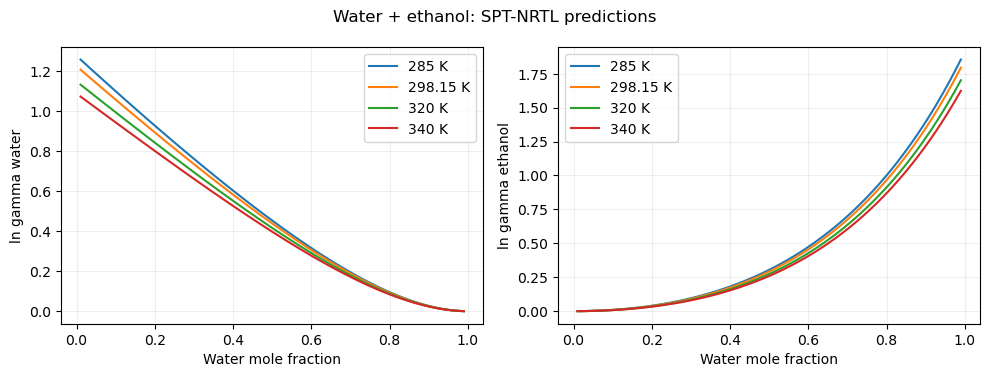

T=285.00 K: HE=678.815 J/mol; CpE=1.23696 J/(mol K)
T=298.15 K: HE=692.770 J/mol; CpE=0.88468 J/(mol K)
T=320.00 K: HE=705.629 J/mol; CpE=0.29081 J/(mol K)
T=340.00 K: HE=705.951 J/mol; CpE=-0.25936 J/(mol K)


In [3]:
xs = np.linspace(0.01, 0.99, 80)
X = np.column_stack([xs, 1-xs])
names = model.components
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for T in [285., 298.15, 320., 340.]:
    lng = model.ln_activity_coefficients_batch(T, X)
    for i, ax in enumerate(axes):
        ax.plot(xs, lng[:, i], label=f"{T:g} K")
for i, ax in enumerate(axes):
    ax.set(xlabel="Water mole fraction", ylabel=f"ln gamma {names[i]}")
    ax.grid(alpha=0.2); ax.legend()
fig.suptitle("Water + ethanol: SPT-NRTL predictions")
fig.tight_layout(); plt.show()

x = np.array([0.4, 0.6])
for T in [285., 298.15, 320., 340.]:
    J = model.ln_activity_coefficients_jacobian(T, x)
    np.testing.assert_allclose(x @ J, 0., atol=1e-13)
    print(f"T={T:.2f} K: HE={model.excess_enthalpy(T,x):.3f} J/mol; "
          f"CpE={model.excess_heat_capacity(T,x):.5f} J/(mol K)")

## Vapour–liquid equilibrium

Use the existing VLE API with ideal vapour and no Poynting correction.
Saturation pressures are separate inputs. Here they come from the cited NIST
Antoine correlations in `data/real_mixtures.json`; their validity intervals are
checked and bar is converted to Pa. We do not infer those intervals for NRTL.

[NIST water correlation](https://webbook.nist.gov/cgi/cbook.cgi?ID=C7732185&Type=ANTOINE) ·
[NIST ethanol correlation](https://webbook.nist.gov/cgi/cbook.cgi?ID=C64175&Type=ANTOINE).

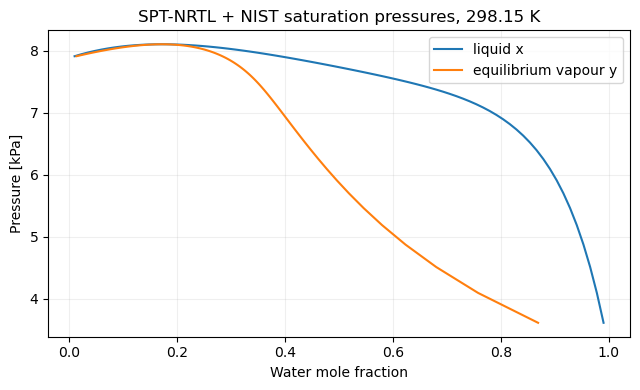

In [4]:
T = 298.15
properties = json.loads(Path("data/real_mixtures.json").read_text())["components"]
psat = []
for name in names:
    p = properties[name]["antoine_bar"]
    assert p["T_min_K"] <= T <= p["T_max_K"]
    psat.append(1e5*10**(p["A"]-p["B"]/(T+p["C"])))
psat = np.array(psat)
results = [bubble_pressure(model, row, T, psat) for row in X]
P = np.array([result.pressure_Pa for result in results])
Y = np.array([result.vapor_composition for result in results])
np.testing.assert_allclose(Y*P[:, None], X*np.exp(model.ln_activity_coefficients_batch(T,X))*psat,
                           rtol=1e-12)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(xs, P/1000, label="liquid x")
ax.plot(Y[:, 0], P/1000, label="equilibrium vapour y")
ax.set(xlabel="Water mole fraction", ylabel="Pressure [kPa]",
       title="SPT-NRTL + NIST saturation pressures, 298.15 K")
ax.grid(alpha=0.2); ax.legend(); fig.tight_layout(); plt.show()

## Reordering, ternary mixtures and offline reuse

Predictions for the two ordered SMILES inputs can differ. The loader selects
one complete source row deterministically and records its order. It maps both
directed tau functions and the shared alpha function into your component order.
Reordering components therefore preserves the physics of an assembled model.

A ternary NRTL model combines predicted binary pairs. This is a modelling
assumption requiring independent validation, particularly for LLE/SLLE.

In [5]:
# The binary source table is already cached: forbid network access.
reverse = NRTL.from_spt({"ethanol": "CCO", "water": "O"}, offline=True)
np.testing.assert_allclose(reverse.ln_activity_coefficients(T, x[::-1]),
                           model.ln_activity_coefficients(T, x)[::-1], atol=1e-14)
print("Offline reload and component-order check passed.")

ternary = NRTL.from_spt({"benzene": "c1ccccc1", "water": "O", "ethanol": "CCO"},
                        database=collection)
print("Ternary component order:", ternary.components)
print("Ternary ln gamma:", ternary.ln_activity_coefficients(T, [0.2, 0.5, 0.3]))
print("Pair records:", len(ternary.metadata["pairs"]))

with tempfile.TemporaryDirectory() as folder:
    path = Path(folder)/"spt-nrtl-model.json"
    ternary.to_json(path)
    # This loads coefficients directly: no RDKit, dataset access or download.
    restored = NRTL.from_json(path)
    np.testing.assert_allclose(restored.ln_activity_coefficients(T, [0.2, 0.5, 0.3]),
                               ternary.ln_activity_coefficients(T, [0.2, 0.5, 0.3]))
    assert restored.metadata == ternary.metadata
    print("Self-contained JSON and provenance round trip passed:", restored.to_dict()["schema"])

Offline reload and component-order check passed.


Ternary component order: ('benzene', 'water', 'ethanol')


Ternary ln gamma: [1.76536902 0.66994932 0.24321741]
Pair records: 3
Self-contained JSON and provenance round trip passed: thermoweave.nrtl.v2


## Fit complexity should follow the data

The full function is needed to retain these SPT predictions exactly. For your
own experimental fits, start with a+b/T and fixed alpha. Add logarithmic/linear
terms only when broad temperature coverage, caloric data and independent
validation justify them. More coefficients can increase correlations and make
extrapolation worse.

The fitting helpers accept all temperature coefficients and use exact JAX
Jacobians. They reject deficient temperature basis combinations, while the fit
report also diagnoses the actual Jacobian rank/conditioning. Alpha terms remain
fixed by default. See the [fitting guide](../advanced/nrtl-fitting.md).

Use `SPTNRTLDatabase(cache_dir=..., offline=True)` for an explicitly managed
cache, or `data_dir=` for a pinned local collection. The
[SPT setup guide](../models/spt-nrtl.md) describes platform defaults,
environment variables, verification and references. Saving a model as JSON is
the smallest way to share a reproducible assembled calculation input.